In [1]:
import os
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Modèles et Ensembles
from sklearn.ensemble import (
    ExtraTreesClassifier,
    HistGradientBoostingClassifier,
    RandomForestClassifier,
    StackingClassifier,
)
from sklearn.linear_model import LogisticRegressionCV
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

# Métriques et Évaluation
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    recall_score,
    fbeta_score,
    roc_curve,
    auc
)

# Fix pour le warning joblib/loky sous Windows
os.environ['LOKY_MAX_CPU_COUNT'] = str(os.cpu_count())

ValueError: numpy.dtype size changed, may indicate binary incompatibility. Expected 96 from C header, got 88 from PyObject

In [7]:
def extract_features_final(pdw):
    """
    Extrait les 28 features (physiques, temporelles, spectrales).
    """
    raw_dates = np.asarray(pdw['date'], dtype=np.float64)
    order = np.argsort(raw_dates)

    dates = raw_dates[order]
    frequences = np.asarray(pdw['frequence'], dtype=np.float64)[order]
    largeurs = np.asarray(pdw['largeur'], dtype=np.float64)[order]
    puissances = np.asarray(pdw['puissance'], dtype=np.float64)[order]
    phi = np.asarray(pdw['phi'], dtype=np.float64)[order]

    features = []

    # --- 1. PHYSIQUE DE PROPAGATION (Distance 3D & Puissance émise) ---
    if len(dates) > 0:
        cos_phi = np.clip(np.abs(np.cos(phi)), 1e-3, 1.0)
        r_km = 10.0 / cos_phi
        p_emitted = puissances + 20.0 * np.log10(r_km)

        r_mean, r_min = float(np.mean(r_km)), float(np.min(r_km))
        p_emit_mean = float(np.mean(p_emitted))
        p_emit_max = float(np.max(p_emitted))
        p_emit_std = float(np.std(p_emitted))
        p_emit_med = float(np.median(p_emitted))
    else:
        r_mean = r_min = p_emit_mean = p_emit_max = p_emit_std = p_emit_med = 0.0

    features.extend([r_mean, r_min, p_emit_mean, p_emit_max, p_emit_std, p_emit_med])

    # --- 2. PRI (Robuste au mitage) ---
    if len(dates) > 1:
        raw_pri = np.diff(dates)
        valid_pri = raw_pri[(raw_pri > 0.0) & (raw_pri < 100.0)]
        if len(valid_pri) > 0:
            pri_q10, pri_q25, pri_q50, pri_q75 = np.percentile(valid_pri, [10, 25, 50, 75])
            pri_std = float(np.std(valid_pri))
            counts, bin_edges = np.histogram(valid_pri, bins=np.arange(0, 100, 0.05))
            pri_mode = float(bin_edges[np.argmax(counts)])
        else:
            pri_q10 = pri_q25 = pri_q50 = pri_q75 = pri_std = pri_mode = 0.0
    else:
        pri_q10 = pri_q25 = pri_q50 = pri_q75 = pri_std = pri_mode = 0.0

    features.extend([pri_q10, pri_q25, pri_q50, pri_q75, pri_std, pri_mode])

    # --- 3. FRÉQUENCE ---
    if len(frequences) > 0:
        f_mean, f_std = float(np.mean(frequences)), float(np.std(frequences))
        f_q10, f_q50, f_q90 = np.percentile(frequences, [10, 50, 90])
        f_span = float(f_q90 - f_q10)
    else:
        f_mean = f_std = f_q10 = f_q50 = f_q90 = f_span = 0.0

    features.extend([f_mean, f_std, f_q10, f_q50, f_q90, f_span])

    # --- 4. LARGEUR & PUISSANCE REÇUE ---
    for var in [largeurs, puissances]:
        if len(var) > 0:
            features.extend([
                float(np.mean(var)), float(np.std(var)),
                float(np.median(var)), float(np.max(var))
            ])
        else:
            features.extend([0.0, 0.0, 0.0, 0.0])

    # --- 5. ACTIVITÉ & DENSITÉ ---
    n_imp = float(len(dates))
    duration = float(dates[-1] - dates[0]) if len(dates) > 1 else 1.0
    density = n_imp / (duration + 1e-5)

    features.extend([n_imp, density])

    return np.array(features, dtype=np.float64)


def load_dataset_final(data_dir, labels_json_path):
    with open(labels_json_path, 'r') as f:
        labels_dict = json.load(f)

    X, y = [], []
    data_path = Path(data_dir)

    for fname, label in labels_dict.items():
        filepath = data_path / f'{fname}.npz'
        if not filepath.exists():
            continue
        
        pdw = np.load(filepath)
        X.append(extract_features_final(pdw))
        y.append(1 if label == 'menace' else 0)

    return np.array(X), np.array(y)

In [8]:
feature_names = [
    # Physique (6)
    'r_mean', 'r_min', 'p_emit_mean', 'p_emit_max', 'p_emit_std', 'p_emit_med',
    # PRI (6)
    'pri_q10', 'pri_q25', 'pri_q50', 'pri_q75', 'pri_std', 'pri_mode',
    # Fréquence (6)
    'freq_mean', 'freq_std', 'freq_q10', 'freq_q50', 'freq_q90', 'freq_span',
    # Largeur (4)
    'largeur_mean', 'largeur_std', 'largeur_median', 'largeur_max',
    # Puissance reçue (4)
    'puissance_mean', 'puissance_std', 'puissance_median', 'puissance_max',
    # Activité (2)
    'n_impulsions', 'density'
]


# Chargement
raw_tr, y_tr = load_dataset_final('./donnees/train', './donnees/train_labels.json')
raw_va, y_va = load_dataset_final('./donnees/valid', './donnees/valid_labels.json')
raw_te,  y_te  = load_dataset_final('./donnees/test', './donnees/test_labels.json')

# Dataframes épurés
X_tr = pd.DataFrame(raw_tr, columns=feature_names)[feature_names]
X_va = pd.DataFrame(raw_va, columns=feature_names)[feature_names]
X_te  = pd.DataFrame(raw_te, columns=feature_names)[feature_names]

In [9]:
# 1. On retire LightGBM qui cause l'erreur d'accès mémoire sous Windows (Anaconda)
# 2. On utilise les modèles natifs de scikit-learn + XGBoost
# 3. CRUCIAL : On désactive le parallélisme du StackingClassifier (n_jobs=None)
#    et on laisse CHAQUE estimateur individuel utiliser tous les cœurs (n_jobs=-1)

estimators = [
    (
        'rf',
        RandomForestClassifier(
            n_estimators=300, max_depth=12, random_state=42, n_jobs=-1
        ),
    ),
    (
        'et',
        ExtraTreesClassifier(
            n_estimators=300, max_depth=12, random_state=42, n_jobs=-1
        ),
    ),
    (
        'hgb',
        HistGradientBoostingClassifier(
            max_iter=300,
            learning_rate=0.03,
            max_leaf_nodes=25,
            l2_regularization=1.0,
            random_state=42,
        ),
    ),
    (
        'xgb',
        XGBClassifier(
            n_estimators=250,
            learning_rate=0.03,
            max_depth=5,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=42,
            n_jobs=-1, # XGBoost utilise ses propres threads
        ),
    ),
]

# Stacking Classifier SANS joblib en surcouche
stack_model = StackingClassifier(
    estimators=estimators,
    final_estimator=LogisticRegressionCV(cv=5),
    cv=5,
    n_jobs=None,  # <-- C'est ici que l'on empêche le crash
)

# Entraînement
print("Entraînement du Stacking Classifier en cours...")
stack_model.fit(X_tr, y_tr)
print("Entraînement terminé !")

Entraînement du Stacking Classifier en cours...


c:\Users\pchey\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:110: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] Le fichier spécifié est introuvable
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\pchey\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 199, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\pchey\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\pchey\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\pchey\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(e

Entraînement terminé !


In [10]:
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

def boot_ci(y, pred, B=2000, seed=0):
    r = np.random.default_rng(seed); n = len(y)
    accs = [(y[i] == pred[i]).mean() for i in (r.integers(0, n, n) for _ in range(B))]
    return np.percentile(accs, [2.5, 97.5])

modeles = {
    'dummy (majoritaire)': DummyClassifier(strategy='most_frequent'),
    'stump (1 split)':     DecisionTreeClassifier(max_depth=1, random_state=0),
    'logreg + scaler':     make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    'random forest':       RandomForestClassifier(n_estimators=300, max_depth=12, random_state=42, n_jobs=-1),
    'hist gradient boost': HistGradientBoostingClassifier(max_iter=300, learning_rate=0.03, max_leaf_nodes=25,
                                                          l2_regularization=1.0, random_state=42),
}
res = []
for nom, m in modeles.items():
    m.fit(X_tr, y_tr)
    p = m.predict(X_va)
    lo, hi = boot_ci(y_va, p)
    res.append((nom, accuracy_score(y_va, p), lo, hi))
p = stack_model.predict(X_va)
lo, hi = boot_ci(y_va, p)
res.append(('stacking (ton modèle)', accuracy_score(y_va, p), lo, hi))

print(pd.DataFrame(res, columns=['modèle', 'acc_valid', 'IC95_bas', 'IC95_haut']).round(3).to_string(index=False))
print("\nMatrice de confusion du stump :\n", confusion_matrix(y_va, modeles['stump (1 split)'].predict(X_va)))

               modèle  acc_valid  IC95_bas  IC95_haut
  dummy (majoritaire)      0.485     0.452      0.516
      stump (1 split)      0.634     0.604      0.665
      logreg + scaler      0.703     0.676      0.731
        random forest      0.822     0.798      0.846
  hist gradient boost      0.807     0.783      0.832
stacking (ton modèle)      0.820     0.795      0.845

Matrice de confusion du stump :
 [[420  95]
 [271 214]]


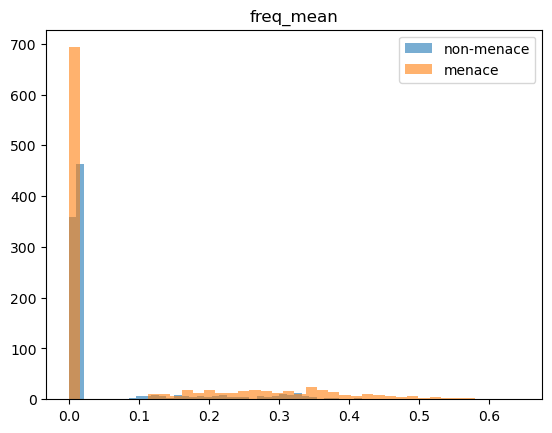

In [12]:
def hist_par_classe(valeurs, y, titre, bins=40):
    """Histogramme superposé menace / non-menace pour une grandeur donnée."""
    valeurs, y = np.asarray(valeurs), np.asarray(y)
    ok = np.isfinite(valeurs)
    plt.hist(valeurs[ok & (y == 0)], bins=bins, alpha=.6, label='non-menace')
    plt.hist(valeurs[ok & (y == 1)], bins=bins, alpha=.6, label='menace')
    plt.title(titre); plt.legend(); plt.show()

# exemple
hist_par_classe(X_tr['freq_std'], y_tr, 'freq_mean')

In [16]:
X_tr.head()
print(np.shape(X_tr))


(2000, 28)


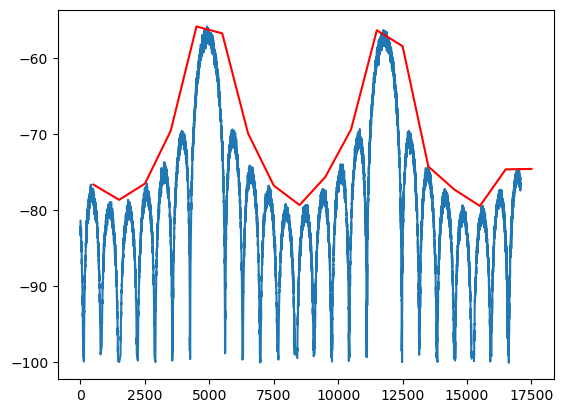

In [42]:
pdws = np.load('./donnees/train/pdw-126.npz')

o = np.argsort(pdws['date'])
d = np.array(pdws['date'])[o]
p = np.array(pdws['puissance'])[o]


def serie_puissance(r, pas_ms=100, fill=-100.0):
    """Retourne (t_centres, p_max) : puissance max (dB) par fenêtre de pas_ms.
    Les fenêtres sans impulsion valent `fill`."""
    # 1. float64 dès le départ (les données brutes sont en float16)
    d = np.asarray(r['date'], dtype=np.float64)
    p = np.asarray(r['puissance'], dtype=np.float64)

    # 2. tri chronologique
    o = np.argsort(d)
    d, p = d[o], p[o]

    # 3. indice de fenêtre de chaque impulsion (division entière)
    idx = ((d - d[0]) // pas_ms).astype(int)

    # 4. tableau initialisé aux trous, puis max par fenêtre en une passe
    p_max = np.full(idx.max() + 1, fill)
    np.maximum.at(p_max, idx, p)

    # 5. centre de chaque fenêtre
    t_centres = d[0] + (np.arange(len(p_max)) + 0.5) * pas_ms
    return t_centres, p_max


t_centres, max = serie_puissance(pdws,1000)
plt.plot(d,p)
plt.plot(t_centres,max,c='r')

1186
pas=  50 ms : 224 fenêtres, 84.8% de fenêtres vides, max série = -88.9 dB, max brut = -88.9 dB


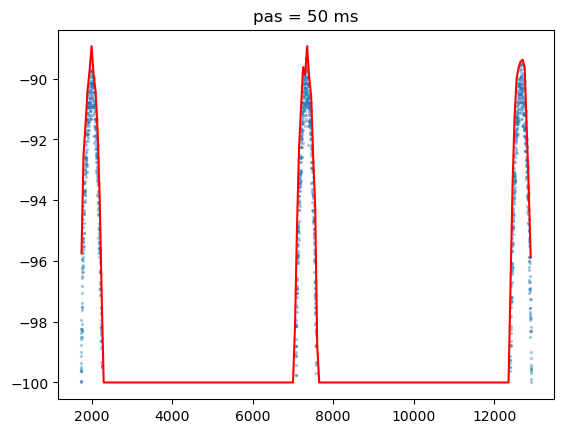

pas= 100 ms : 112 fenêtres, 83.9% de fenêtres vides, max série = -88.9 dB, max brut = -88.9 dB


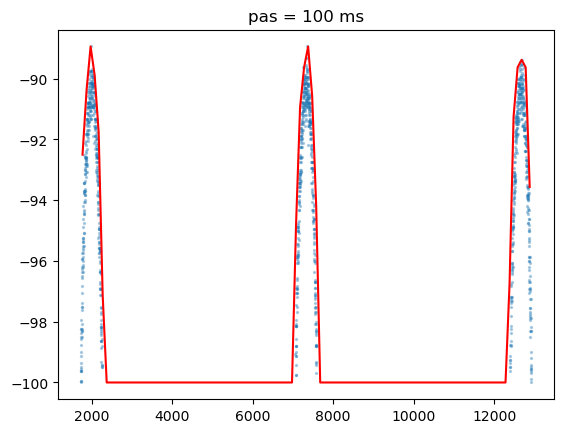

pas= 200 ms : 56 fenêtres, 82.1% de fenêtres vides, max série = -88.9 dB, max brut = -88.9 dB


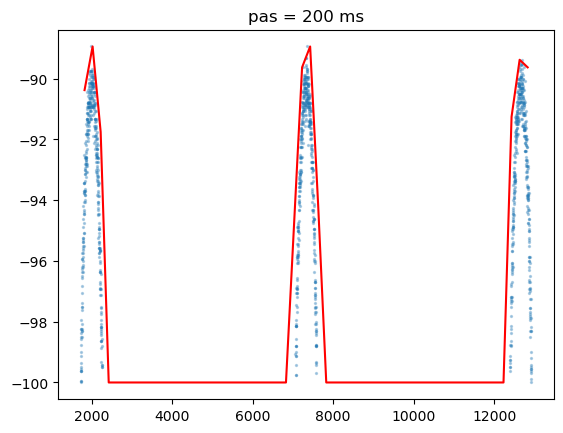

In [49]:
r = np.load('./donnees/train/pdw-30.npz')
d_all = np.asarray(r['date'], dtype=np.float64)
p_all = np.asarray(r['puissance'], dtype=np.float64)

print(len(d_all))

for pas in [50, 100, 200]:
    t, pm = serie_puissance(r, pas)
    print(f"pas={pas:4d} ms : {len(pm)} fenêtres, "
          f"{np.mean(pm == -100):.1%} de fenêtres vides, "
          f"max série = {pm.max():.1f} dB, max brut = {p_all.max():.1f} dB")
    plt.scatter(d_all, p_all, s=2, alpha=.3)
    plt.plot(t, pm, c='r'); plt.title(f'pas = {pas} ms'); plt.show()

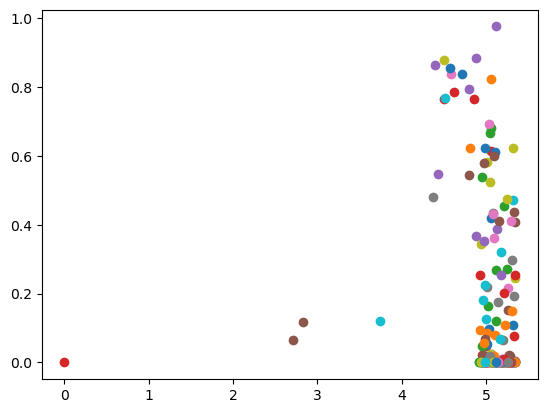

In [50]:
for i in range(200):
    f = f"./donnees/train/pdw-{i}.npz"
    r = np.load(f)
    t, pm = serie_puissance(r, 100)
    moy = np.mean(pm == -100)
    n = len(t)
    plt.scatter(np.log(n),moy)


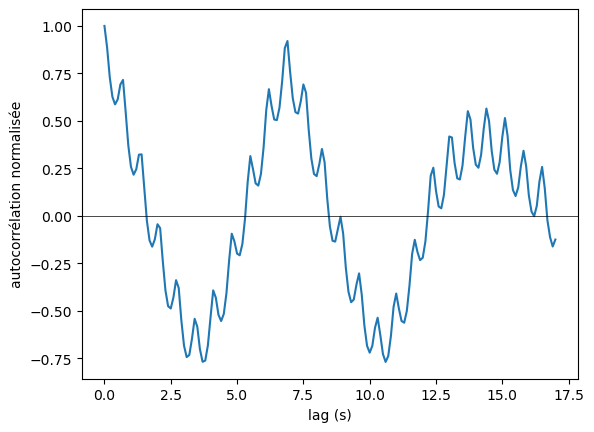

In [56]:
r = np.load('./donnees/train/pdw-126.npz')
pas = 100                                  # ms
t, pm = serie_puissance(r, pas)

x = pm - pm.mean()
N = len(x)

ac = np.correlate(x, x, 'full')[N-1:]      # lags 0 .. N-1 (moitié droite, par position)
ac = ac/(N - np.arange(N))
ac = ac / ac[0]                            # normalisation : ac[0] = 1
lags_s = np.arange(N) * pas / 1000         # secondes

plt.plot(lags_s, ac)
plt.xlabel('lag (s)'); plt.ylabel('autocorrélation normalisée')
plt.axhline(0, c='k', lw=.5); plt.show()


200 signaux chargés, proportion de menaces : 0.435
NaN : 4
y                      0      1
periode    count  110.00  86.00
           mean     5.23   4.66
           std      2.17   1.79
           min      2.10   2.10
           25%      3.42   3.10
           50%      5.50   4.75
           75%      7.07   6.18
           max      9.70   7.80
hauteur    count  110.00  86.00
           mean     0.72   0.90
           std      0.40   0.28
           min     -0.14  -0.14
           25%      0.35   0.95
           50%      0.96   0.98
           75%      1.00   1.00
           max      1.20   1.19
n_periodes count  110.00  86.00
           mean     3.84   4.11
           std      1.91   1.79
           min      2.01   2.03
           25%      2.29   2.65
           50%      3.13   3.49
           75%      4.62   5.39
           max      9.05   9.32


C:\Users\pchey\AppData\Local\Temp\ipykernel_31936\4036316674.py:30: RuntimeWarning: invalid value encountered in divide
  ac = ac / ac[0]                        # Normalisation à 1 pour lag=0


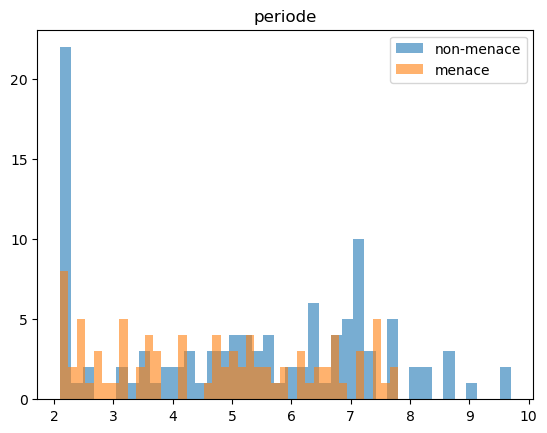

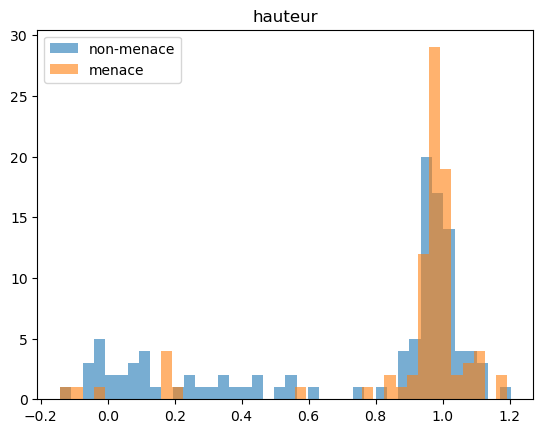

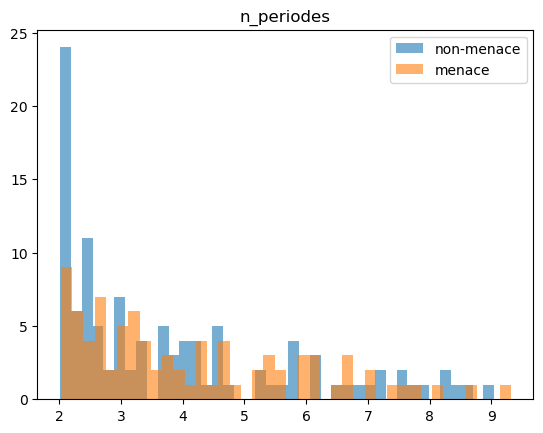

AUC période : 0.43


In [74]:

def charger_signaux(data_dir, labels_json_path, n_max=None):
    """Retourne la liste des PDW bruts, les labels (0/1) et les noms, dans le même ordre."""
    with open(labels_json_path) as f:
        labels_dict = json.load(f)
    raws, y, names = [], [], []
    for fname, label in list(labels_dict.items())[:n_max]:
        p = Path(data_dir) / f'{fname}.npz'
        if not p.exists():
            continue
        with np.load(p) as z:
            raws.append({k: z[k] for k in z.files})
        y.append(1 if label == 'menace' else 0)
        names.append(fname)
    return raws, np.array(y), names

raw_tr, y_tr, names_tr = charger_signaux('./donnees/train', './donnees/train_labels.json', n_max=200)
print(len(raw_tr), "signaux chargés, proportion de menaces :", y_tr.mean().round(3))

from sklearn.metrics import roc_auc_score


def periode_balayage(r, pas=100):
    t, pm = serie_puissance(r, pas)
    
    x = pm - np.mean(pm)
    N = len(x)
    
    ac = np.correlate(x, x, 'full')[N-1:]  # lags 0 .. N-1
    #ac = ac / (N - np.arange(N))           # Normalisation par le nombre de points
    ac = ac / ac[0]                        # Normalisation à 1 pour lag=0
    
    lags_s = np.arange(N) * pas / 1000  
    
    masque = (lags_s > 2) & (np.arange(N) < N // 2)

    lags_valides = lags_s[masque]
    ac_valides = ac[masque]
    
    idx_max = np.argmax(ac_valides)
    k = np.where(masque)[0][idx_max]   # vrai indice de lag
    
    return lags_valides[idx_max], ac_valides[idx_max]*(N)/(N-k),lags_s[-1]/lags_valides[idx_max]


resultats = []
for r, lab, nom in zip(raw_tr, y_tr, names_tr):
    try:
        per, h, n_per = periode_balayage(r)
    except Exception:
        per, h, n_per = np.nan, np.nan, np.nan
    resultats.append((nom, lab, per, h, n_per))

R = pd.DataFrame(resultats, columns=['nom', 'y', 'periode', 'hauteur', 'n_periodes'])
print("NaN :", R.periode.isna().sum())
print(R.groupby('y')[['periode', 'hauteur', 'n_periodes']].describe().T.round(2).to_string())

for col in ['periode', 'hauteur', 'n_periodes']:
    hist_par_classe(R[col], R['y'], col)

ok = R.periode.notna()
print("AUC période :", roc_auc_score(R.y[ok], R.periode[ok]).round(3))

In [75]:
from scipy.signal import find_peaks

def periode_balayage(r, pas=100, lineaire=False, prominence=0.1):
    """Retourne (période en s, hauteur corrigée du biais, nb de périodes), ou NaN."""
    t, pm = serie_puissance(r, pas)
    if lineaire:
        pm = 10 ** (pm / 10)                 # échelle linéaire : les trous pèsent ~0
    x = pm - pm.mean()
    N = len(x)
    if N < 10 or np.all(x == 0):             # fichier trop court ou série constante
        return np.nan, np.nan, np.nan

    ac = np.correlate(x, x, 'full')[N-1:]
    ac = ac / ac[0]

    neg = np.where(ac < 0)[0]                # premier passage sous zéro
    if len(neg) == 0:
        return np.nan, np.nan, np.nan
    start = neg[0]
    pk, _ = find_peaks(ac[start:N // 2], prominence=prominence)
    if len(pk) == 0:
        return np.nan, np.nan, np.nan

    k = start + pk[0]                        # vrai indice de lag du premier pic marqué
    return k * pas / 1000, ac[k] * N / (N - k), N / k

In [76]:
raw_tr, y_tr, names_tr = charger_signaux('./donnees/train', './donnees/train_labels.json')
raw_va, y_va, names_va = charger_signaux('./donnees/valid', './donnees/valid_labels.json')

def feats_balayage(raws, **kw):
    out = []
    for r in raws:
        try:
            out.append(periode_balayage(r, **kw))
        except Exception:
            out.append((np.nan,) * 3)
    return pd.DataFrame(out, columns=['scan_periode', 'scan_hauteur', 'scan_nper'])

for nom, kw in [('dB', dict(lineaire=False)), ('linéaire', dict(lineaire=True))]:
    Btr = feats_balayage(raw_tr, **kw)
    ok = Btr.scan_hauteur.notna()
    print(nom, "| NaN :", (~ok).sum(),
          "| AUC période :", roc_auc_score(y_tr[Btr.scan_periode.notna()], Btr.scan_periode.dropna()).round(3),
          "| AUC hauteur :", roc_auc_score(y_tr[ok], Btr.scan_hauteur[ok]).round(3))

dB | NaN : 452 | AUC période : 0.419 | AUC hauteur : 0.609
linéaire | NaN : 564 | AUC période : 0.286 | AUC hauteur : 0.429


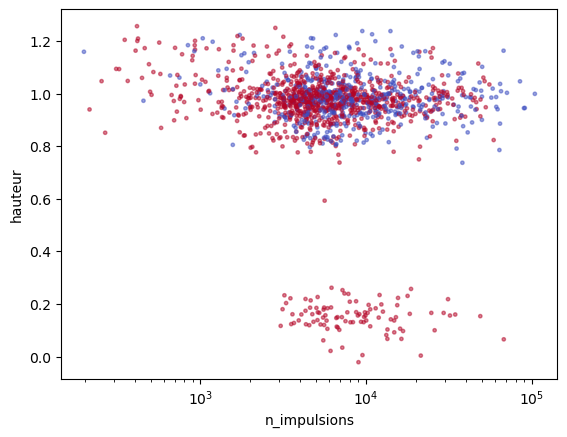

In [81]:
Btr = feats_balayage(raw_tr, lineaire=True)          # choisis dB ou linéaire d'après §2
n_tr = np.array([len(r['date']) for r in raw_tr])
plt.scatter(n_tr, Btr.scan_hauteur, c=y_tr, cmap='coolwarm', s=6, alpha=.5)
plt.xscale('log'); plt.xlabel('n_impulsions'); plt.ylabel('hauteur'); plt.show()

In [82]:
Bva = feats_balayage(raw_va, lineaire=True)           # même choix que ci-dessus

# X_train / X_valid : tes 23 features, même ordre que charger_signaux (JSON)
Xtr2 = pd.concat([X_tr.reset_index(drop=True), Btr], axis=1)
Xva2 = pd.concat([X_va.reset_index(drop=True), Bva], axis=1)

def hgb():
    return HistGradientBoostingClassifier(max_iter=300, learning_rate=0.03, max_leaf_nodes=25,
                                          l2_regularization=1.0, random_state=42)

def paired_boot(y, pa, pb, B=5000, seed=0):
    """IC95 de acc(a) - acc(b) sur les mêmes fichiers (bootstrap apparié)."""
    y, pa, pb = np.asarray(y), np.asarray(pa), np.asarray(pb)
    rg = np.random.default_rng(seed); n = len(y)
    ca, cb = (pa == y).astype(int), (pb == y).astype(int)
    diffs = [(ca[i] - cb[i]).mean() for i in (rg.integers(0, n, n) for _ in range(B))]
    return np.percentile(diffs, [2.5, 97.5])

m0 = hgb().fit(X_tr, y_tr)
m1 = hgb().fit(Xtr2, y_tr)                          # HGB gère les NaN nativement
p0, p1 = m0.predict(X_va), m1.predict(Xva2)
print(f"sans balayage : {accuracy_score(y_va, p0):.3f} | avec : {accuracy_score(y_va, p1):.3f}")
print("IC95 de la différence (appariée) :", paired_boot(y_va, p1, p0))

sans balayage : 0.807 | avec : 0.856
IC95 de la différence (appariée) : [0.028 0.069]


In [ ]:
Btr = feats_balayage(raw_tr, lineaire=True)
Bva = feats_balayage(raw_va, lineaire=True)

print("Taux de menaces | NaN :", y_tr[Btr.scan_hauteur.isna().values].mean().round(3),
      "| non-NaN :", y_tr[Btr.scan_hauteur.notna().values].mean().round(3))

def hgb(seed):
    return HistGradientBoostingClassifier(max_iter=300, learning_rate=0.03, max_leaf_nodes=25,
                                          l2_regularization=1.0, random_state=seed)

Xtr2 = pd.concat([X_tr.reset_index(drop=True), Btr], axis=1)
Xva2 = pd.concat([X_va.reset_index(drop=True), Bva], axis=1)
Xtr3 = X_tr.reset_index(drop=True).assign(scan_nan=Btr.scan_hauteur.isna().astype(int).values)
Xva3 = X_va.reset_index(drop=True).assign(scan_nan=Bva.scan_hauteur.isna().astype(int).values)

res = {'base': [], 'balayage': [], 'indicateur NaN seul': []}
for s in range(5):
    res['base'].append(accuracy_score(y_va, hgb(s).fit(X_tr, y_tr).predict(X_va)))
    res['balayage'].append(accuracy_score(y_va, hgb(s).fit(Xtr2, y_tr).predict(Xva2)))
    res['indicateur NaN seul'].append(accuracy_score(y_va, hgb(s).fit(Xtr3, y_tr).predict(Xva3)))
for k, v in res.items():
    print(f"{k:22s} {np.mean(v):.3f} +/- {np.std(v):.3f}")

    

Taux de menaces | NaN : 0.138 | non-NaN : 0.65
base                   0.807 +/- 0.000
balayage               0.856 +/- 0.000
indicateur NaN seul    0.830 +/- 0.000


In [86]:
def paired_boot(y, pa, pb, B=5000, seed=0):
    """IC95 de acc(a) - acc(b) sur les mêmes fichiers (bootstrap apparié)."""
    y, pa, pb = np.asarray(y), np.asarray(pa), np.asarray(pb)
    rg = np.random.default_rng(seed); n = len(y)
    ca, cb = (pa == y).astype(int), (pb == y).astype(int)
    diffs = [(ca[i] - cb[i]).mean() for i in (rg.integers(0, n, n) for _ in range(B))]
    return np.percentile(diffs, [2.5, 97.5])

m0 = hgb(s).fit(X_tr, y_tr)
m1 = hgb(s).fit(Xtr2, y_tr)                          # HGB gère les NaN nativement
p0, p1 = m0.predict(X_va), m1.predict(Xva2)
print(f"sans balayage : {accuracy_score(y_va, p0):.3f} | avec : {accuracy_score(y_va, p1):.3f}")
print("IC95 de la différence (appariée) :", paired_boot(y_va, p1, p0))

sans balayage : 0.807 | avec : 0.856
IC95 de la différence (appariée) : [0.028 0.069]


IC95 acc(balayage) - acc(indicateur NaN) : [0.01  0.042]
NaN, série courte      n=    7  taux de menaces=0.143
NaN, sans pic marqué   n=  557  taux de menaces=0.138
non-NaN                n= 1436  taux de menaces=0.650


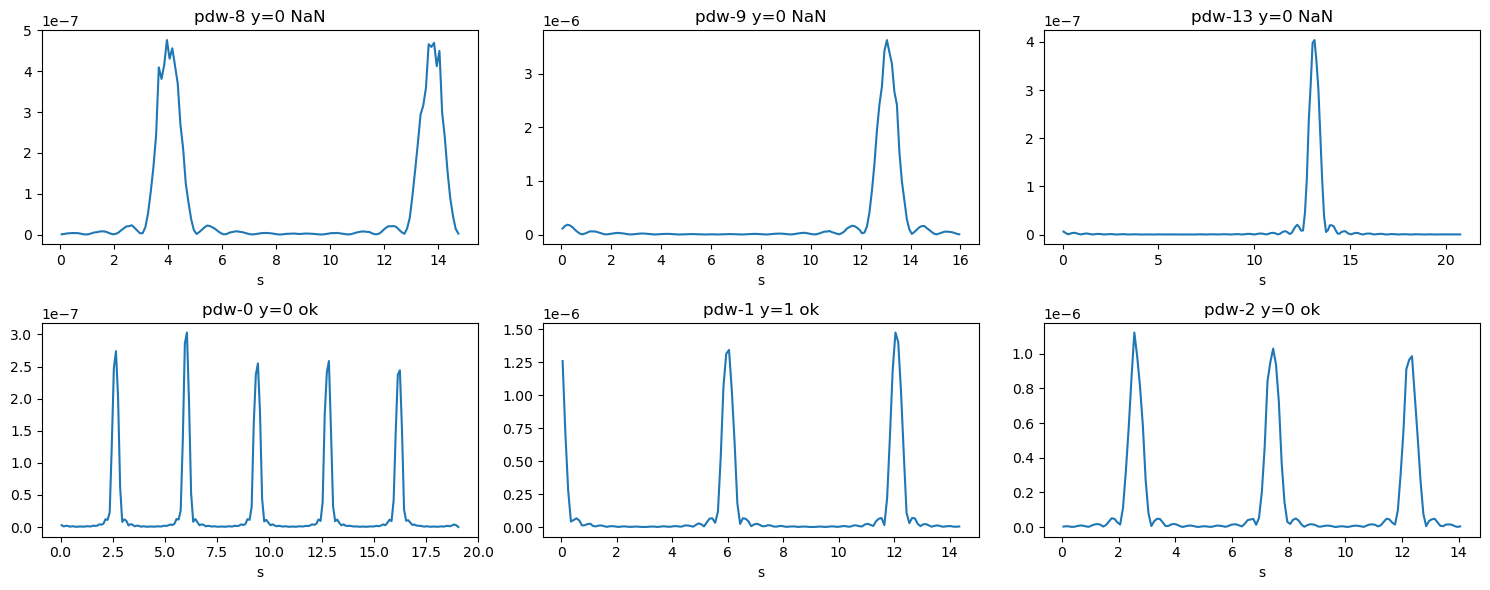

In [87]:
# 1) Période + hauteur apportent-elles quelque chose au-delà de l'indicateur NaN ?
p2 = hgb(0).fit(Xtr2, y_tr).predict(Xva2)
p3 = hgb(0).fit(Xtr3, y_tr).predict(Xva3)
print("IC95 acc(balayage) - acc(indicateur NaN) :", paired_boot(y_va, p2, p3))

# 2) Causes des NaN : série courte ou aucun pic marqué ?
N_tr = np.array([len(serie_puissance(r, 100)[1]) for r in raw_tr])
isnan = Btr.scan_hauteur.isna().values
court = N_tr < 10
for nom, m in [("NaN, série courte", isnan & court),
               ("NaN, sans pic marqué", isnan & ~court),
               ("non-NaN", ~isnan)]:
    print(f"{nom:22s} n={m.sum():5d}  taux de menaces={y_tr[m].mean():.3f}")

# 3) Séries de puissance : 3 NaN sans pic, 3 non-NaN
idx_nan = np.where(isnan & ~court)[0][:3]
idx_ok = np.where(~isnan)[0][:3]
fig, ax = plt.subplots(2, 3, figsize=(15, 6))
for a, i in zip(ax.ravel(), list(idx_nan) + list(idx_ok)):
    t, pm = serie_puissance(raw_tr[i], 100)
    a.plot(t / 1000, 10 ** (pm / 10))
    a.set(title=f"{names_tr[i]} y={y_tr[i]} {'NaN' if isnan[i] else 'ok'}", xlabel='s')
plt.tight_layout(); plt.show()

In [88]:
reps = ['pri_q10', 'pri_std', 'freq_mean', 'freq_std', 'largeur_mean',
        'puissance_mean', 'puissance_max', 'p_emit_std', 'n_impulsions']
scan = ['scan_periode', 'scan_hauteur', 'scan_nper']

jeux = {
    '23 features':               (X_tr.reset_index(drop=True), X_va.reset_index(drop=True)),
    '23 + balayage':             (Xtr2, Xva2),
    '9 représentants':           (X_tr[reps].reset_index(drop=True), X_va[reps].reset_index(drop=True)),
    '9 représentants + balayage': (pd.concat([X_tr[reps].reset_index(drop=True), Btr[scan]], axis=1),
                                   pd.concat([X_va[reps].reset_index(drop=True), Bva[scan]], axis=1)),
}
preds = {}
for nom, (A, B) in jeux.items():
    preds[nom] = hgb(0).fit(A, y_tr).predict(B)
    print(f"{nom:28s} acc valid = {accuracy_score(y_va, preds[nom]):.3f}")

print("IC95 (9 rep + balayage) - (23 + balayage) :",
      paired_boot(y_va, preds['9 représentants + balayage'], preds['23 + balayage']))

23 features                  acc valid = 0.807
23 + balayage                acc valid = 0.856
9 représentants              acc valid = 0.811
9 représentants + balayage   acc valid = 0.859
IC95 (9 rep + balayage) - (23 + balayage) : [-0.011  0.018]


In [89]:
from scipy.signal import find_peaks, peak_widths

def lobes(r, pas=100, seuil=0.3):
    """Lobes principaux (série linéaire normalisée). Retourne n_lobes, période (s), largeur (s)."""
    t, pm = serie_puissance(r, pas)
    x = 10 ** (pm / 10)
    x = x / x.max()
    pk, _ = find_peaks(x, height=seuil, distance=int(1000 / pas))   # >= 1 s entre lobes
    n = len(pk)
    per = np.median(np.diff(pk)) * pas / 1000 if n >= 2 else np.nan
    larg = np.median(peak_widths(x, pk, rel_height=0.5)[0]) * pas / 1000 if n >= 1 else np.nan
    return n, per, larg

def feats_lobes(raws):
    L = pd.DataFrame([lobes(r) for r in raws], columns=['lobe_n', 'lobe_per', 'lobe_larg'])
    L['lobe_duty'] = L.lobe_larg / L.lobe_per
    L['duree_s'] = [len(serie_puissance(r, 100)[1]) * 0.1 for r in raws]
    return L

Ltr, Lva = feats_lobes(raw_tr), feats_lobes(raw_va)

# Contrôle sur tes 4 fichiers de référence (attendu : ~2, ~6, ~5, ~7 s de période)
for nom, r in [('1316', r_1316), ('1054', r_1054), ('30', r_30), ('126', r_126)]:
    print(nom, [round(v, 2) for v in lobes(r)])

# AUC univariées
for c in ['lobe_n', 'lobe_per', 'lobe_larg', 'lobe_duty']:
    ok = Ltr[c].notna()
    print(f"{c:10s} NaN={(~ok).sum():4d}  AUC train={roc_auc_score(y_tr[ok], Ltr[c][ok]):.3f}")

# Gain en modèle, sur le valid, par rapport à ta meilleure configuration actuelle
base_tr = pd.concat([X_tr[reps].reset_index(drop=True), Btr[scan]], axis=1)
base_va = pd.concat([X_va[reps].reset_index(drop=True), Bva[scan]], axis=1)
jeux2 = {
    '9 rep + balayage (actuel)':   (base_tr, base_va),
    '9 rep + lobes':               (pd.concat([X_tr[reps].reset_index(drop=True), Ltr], axis=1),
                                    pd.concat([X_va[reps].reset_index(drop=True), Lva], axis=1)),
    '9 rep + balayage + lobes':    (pd.concat([base_tr, Ltr], axis=1), pd.concat([base_va, Lva], axis=1)),
}
pr = {}
for nom, (A, B) in jeux2.items():
    pr[nom] = hgb(0).fit(A, y_tr).predict(B)
    print(f"{nom:28s} acc valid = {accuracy_score(y_va, pr[nom]):.3f}")
print("IC95 (+lobes) - actuel :", paired_boot(y_va, pr['9 rep + balayage + lobes'], pr['9 rep + balayage (actuel)']))

1316 [8, 2.1, 0.15]
1054 [3, 6.0, 0.43]
30 [3, 5.35, 0.33]
126 [2, 6.8, 0.64]
lobe_n     NaN=   0  AUC train=0.814
lobe_per   NaN= 219  AUC train=0.199
lobe_larg  NaN=   2  AUC train=0.151
lobe_duty  NaN= 219  AUC train=0.483
9 rep + balayage (actuel)    acc valid = 0.859
9 rep + lobes                acc valid = 0.873
9 rep + balayage + lobes     acc valid = 0.868
IC95 (+lobes) - actuel : [-0.011  0.029]


In [90]:
# 1) Stabilité train / valid
for c in ['lobe_n', 'lobe_per', 'lobe_larg', 'duree_s']:
    ok_t, ok_v = Ltr[c].notna(), Lva[c].notna()
    print(f"{c:10s} AUC train={roc_auc_score(y_tr[ok_t], Ltr[c][ok_t]):.3f}"
          f"  valid={roc_auc_score(y_va[ok_v], Lva[c][ok_v]):.3f}")

# 2) Ablation, sans duree_s ni lobe_duty
R_tr = X_tr[reps].reset_index(drop=True)
R_va = X_va[reps].reset_index(drop=True)
cfg = {
    '9 rep':                          [],
    '9 rep + lobe_larg':              ['lobe_larg'],
    '9 rep + lobe_n + lobe_larg':     ['lobe_n', 'lobe_larg'],
    '9 rep + 3 lobes (n, per, larg)': ['lobe_n', 'lobe_per', 'lobe_larg'],
}
pr = {}
for nom, cols in cfg.items():
    A, B = pd.concat([R_tr, Ltr[cols]], axis=1), pd.concat([R_va, Lva[cols]], axis=1)
    pr[nom] = hgb(0).fit(A, y_tr).predict(B)
    print(f"{nom:32s} acc valid = {accuracy_score(y_va, pr[nom]):.3f}")

# lobes seuls (sans les 9 représentants)
c3 = ['lobe_n', 'lobe_per', 'lobe_larg']
p_seul = hgb(0).fit(Ltr[c3], y_tr).predict(Lva[c3])
print(f"{'3 lobes seuls':32s} acc valid = {accuracy_score(y_va, p_seul):.3f}")

for nom in list(cfg)[1:]:
    print(f"IC95 [{nom}] - [9 rep] :", paired_boot(y_va, pr[nom], pr['9 rep']).round(3))

# 3) Sensibilité de lobe_larg au seuil de détection
for s in [0.2, 0.3, 0.5]:
    v = np.array([lobes(r, seuil=s)[2] for r in raw_tr])
    ok = ~np.isnan(v)
    print(f"seuil={s}  AUC lobe_larg (train) = {roc_auc_score(y_tr[ok], v[ok]):.3f}  NaN={(~ok).sum()}")

lobe_n     AUC train=0.814  valid=0.768
lobe_per   AUC train=0.199  valid=0.224
lobe_larg  AUC train=0.151  valid=0.185
duree_s    AUC train=0.515  valid=0.475
9 rep                            acc valid = 0.811
9 rep + lobe_larg                acc valid = 0.839
9 rep + lobe_n + lobe_larg       acc valid = 0.848
9 rep + 3 lobes (n, per, larg)   acc valid = 0.861
3 lobes seuls                    acc valid = 0.790
IC95 [9 rep + lobe_larg] - [9 rep] : [0.01  0.047]
IC95 [9 rep + lobe_n + lobe_larg] - [9 rep] : [0.016 0.06 ]
IC95 [9 rep + 3 lobes (n, per, larg)] - [9 rep] : [0.027 0.074]
seuil=0.2  AUC lobe_larg (train) = 0.151  NaN=2
seuil=0.3  AUC lobe_larg (train) = 0.151  NaN=2
seuil=0.5  AUC lobe_larg (train) = 0.151  NaN=2


In [91]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, StackingClassifier
from xgboost import XGBClassifier

c3 = ['lobe_n', 'lobe_per', 'lobe_larg']
F_tr = pd.concat([X_tr[reps].reset_index(drop=True), Ltr[c3]], axis=1)
F_va = pd.concat([X_va[reps].reset_index(drop=True), Lva[c3]], axis=1)

imp = lambda: SimpleImputer(strategy='median', add_indicator=True)   # RF/ET/logreg n'acceptent pas les NaN
rf = make_pipeline(imp(), RandomForestClassifier(n_estimators=300, max_depth=12, random_state=42, n_jobs=-1))
et = make_pipeline(imp(), ExtraTreesClassifier(n_estimators=300, max_depth=12, random_state=42, n_jobs=-1))
xg = XGBClassifier(n_estimators=250, learning_rate=0.03, max_depth=5, subsample=0.8,
                   colsample_bytree=0.8, random_state=42, n_jobs=-1)

M = {
    'logreg':   make_pipeline(imp(), StandardScaler(), LogisticRegression(max_iter=2000)),
    'rf':       rf,
    'hgb':      hgb(42),
    'stacking': StackingClassifier([('rf', rf), ('et', et), ('hgb', hgb(42)), ('xgb', xg)],
                                   final_estimator=LogisticRegressionCV(cv=5), cv=5),
}
P_va, pred_va = {}, {}
for nom, m in M.items():
    m.fit(F_tr, y_tr)
    P_va[nom] = m.predict_proba(F_va)[:, 1]
    pred_va[nom] = (P_va[nom] >= 0.5).astype(int)
    print(f"{nom:9s} acc valid = {accuracy_score(y_va, pred_va[nom]):.3f}"
          f"  AUC valid = {roc_auc_score(y_va, P_va[nom]):.3f}")

for nom in ['logreg', 'rf', 'stacking']:
    print(f"IC95 acc({nom}) - acc(hgb) :", paired_boot(y_va, pred_va[nom], pred_va['hgb']).round(3))

logreg    acc valid = 0.780  AUC valid = 0.879
rf        acc valid = 0.850  AUC valid = 0.942
hgb       acc valid = 0.861  AUC valid = 0.951
stacking  acc valid = 0.861  AUC valid = 0.951
IC95 acc(logreg) - acc(hgb) : [-0.107 -0.055]
IC95 acc(rf) - acc(hgb) : [-0.029  0.007]
IC95 acc(stacking) - acc(hgb) : [-0.012  0.013]


In [92]:
final_name = 'hgb'          # change seulement selon la règle ci-dessus

raw_te, y_te, names_te = charger_signaux('./donnees/test', './donnees/test_labels.json')
Lte = feats_lobes(raw_te)
F_te = pd.concat([X_te[reps].reset_index(drop=True), Lte[c3]], axis=1)

# seuils choisis sur le valid
p_va = P_va[final_name]
ts = np.linspace(0.05, 0.95, 91)
t_acc = ts[np.argmax([accuracy_score(y_va, p_va >= t) for t in ts])]
fpr_v, tpr_v, thr_v = roc_curve(y_va, p_va)
t_rec = thr_v[np.argmax(tpr_v >= 0.90)]                 # recall >= 0.90 sur valid
print(f"modèle = {final_name} | seuil max-accuracy = {t_acc:.2f} | seuil recall 0.90 = {t_rec:.2f}")

p_te = M[final_name].predict_proba(F_te)[:, 1]
print(f"AUC test = {roc_auc_score(y_te, p_te):.3f}")

def boot_ci(y, pred, B=2000, seed=0):
    rg = np.random.default_rng(seed); n = len(y)
    return np.percentile([(y[i] == pred[i]).mean() for i in (rg.integers(0, n, n) for _ in range(B))], [2.5, 97.5])

for nom, t in [('max-accuracy', t_acc), ('recall 0.90 (valid)', t_rec)]:
    pred = (p_te >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_te, pred).ravel()
    lo, hi = boot_ci(y_te, pred)
    print(f"\n[{nom}] seuil={t:.2f}  acc={accuracy_score(y_te, pred):.3f} IC95=[{lo:.3f}, {hi:.3f}]"
          f"  recall={tp/(tp+fn):.3f}  FPR={fp/(fp+tn):.3f}")
    print(confusion_matrix(y_te, pred))

modèle = hgb | seuil max-accuracy = 0.71 | seuil recall 0.90 = 0.42
AUC test = 0.955

[max-accuracy] seuil=0.71  acc=0.864 IC95=[0.842, 0.885]  recall=0.803  FPR=0.071
[[448  34]
 [102 416]]

[recall 0.90 (valid)] seuil=0.42  acc=0.873 IC95=[0.851, 0.893]  recall=0.898  FPR=0.154
[[408  74]
 [ 53 465]]


In [93]:
from sklearn.inspection import permutation_importance

hg = hgb(42).fit(F_tr, y_tr)
imp_res = permutation_importance(hg, F_va, y_va, n_repeats=20, random_state=0, scoring='accuracy')
print(pd.Series(imp_res.importances_mean, index=F_va.columns).sort_values(ascending=False).round(3).to_string())

# erreurs du valid selon le nombre d'impulsions
n_va = np.array([len(r['date']) for r in raw_va])
err = (hg.predict(F_va) != y_va)
print(pd.Series(err).groupby(pd.qcut(n_va, 4)).mean().round(3))

lobe_per          0.175
lobe_larg         0.099
freq_std          0.044
freq_mean         0.034
pri_q10           0.023
largeur_mean      0.018
n_impulsions      0.017
puissance_mean    0.002
puissance_max     0.001
pri_std          -0.001
lobe_n           -0.002
p_emit_std       -0.004
(3.999, 3659.25]        0.124
(3659.25, 6001.5]       0.128
(6001.5, 11199.75]      0.144
(11199.75, 100313.0]    0.160
dtype: float64


12 features : 0.861 | 7 features : 0.863
IC95 acc(7) - acc(12) : [-0.013  0.017]


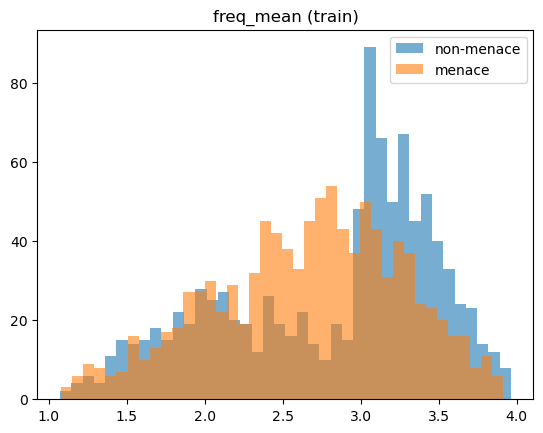

             mean  count
(0.0, 2.0]  0.503    332
(2.0, 2.5]  0.598    366
(2.5, 3.0]  0.705    431
(3.0, 3.5]  0.370    665
(3.5, 5.0]  0.369    206
lobes              chute = 0.275 +/- 0.014
freq               chute = 0.066 +/- 0.006
pri                chute = 0.024 +/- 0.008
activité           chute = 0.016 +/- 0.005
puissance_largeur  chute = 0.020 +/- 0.006


In [94]:
# 1) Jeu réduit : sur valid, perd-on quelque chose en retirant les features d'importance ~0 ?
c7 = ['lobe_per', 'lobe_larg', 'freq_std', 'freq_mean', 'pri_q10', 'largeur_mean', 'n_impulsions']
p12 = hgb(42).fit(F_tr, y_tr).predict(F_va)
p7 = hgb(42).fit(F_tr[c7], y_tr).predict(F_va[c7])
print(f"12 features : {accuracy_score(y_va, p12):.3f} | 7 features : {accuracy_score(y_va, p7):.3f}")
print("IC95 acc(7) - acc(12) :", paired_boot(y_va, p7, p12).round(3))

# 2) Les features de fréquence sont-elles un raccourci de bande ?
for c in ['freq_mean']:
    hist_par_classe(X_tr[c], y_tr, f"{c} (train)")
f = X_tr['freq_mean'].values
bandes = pd.cut(f, bins=[0, 2, 2.5, 3, 3.5, 5])
print(pd.Series(y_tr).groupby(bandes).agg(['mean', 'count']).round(3))

# 3) Importance par groupes (corrige l'effet de la corrélation)
groupes = {
    'lobes':    ['lobe_per', 'lobe_larg', 'lobe_n'],
    'freq':     ['freq_std', 'freq_mean'],
    'pri':      ['pri_q10', 'pri_std'],
    'activité': ['n_impulsions'],
    'puissance_largeur': ['puissance_mean', 'puissance_max', 'p_emit_std', 'largeur_mean'],
}
hg = hgb(42).fit(F_tr, y_tr)
base = accuracy_score(y_va, hg.predict(F_va))
rg = np.random.default_rng(0)
for g, cols in groupes.items():
    chutes = []
    for _ in range(20):
        Xp = F_va.copy()
        Xp[cols] = Xp[cols].iloc[rg.permutation(len(Xp))].to_numpy()
        chutes.append(base - accuracy_score(y_va, hg.predict(Xp)))
    print(f"{g:18s} chute = {np.mean(chutes):.3f} +/- {np.std(chutes):.3f}")

In [95]:
# Dépendance du modèle à la bande de fréquence (valid uniquement)
sans_freq = [c for c in F_tr.columns if not c.startswith('freq')]
p_nf = hgb(42).fit(F_tr[sans_freq], y_tr).predict(F_va[sans_freq])
print(f"avec freq : {accuracy_score(y_va, p12):.3f} | sans freq : {accuracy_score(y_va, p_nf):.3f}")
print("IC95 acc(sans freq) - acc(avec freq) :", paired_boot(y_va, p_nf, p12).round(3))

avec freq : 0.861 | sans freq : 0.818
IC95 acc(sans freq) - acc(avec freq) : [-0.064 -0.023]


In [97]:
from scipy.stats import spearmanr

# --- A) PRI sur la fenêtre où la résolution est fine (< 512 ms) ---
def pri_debut(r, fin=512):
    d = np.sort(np.asarray(r['date'], dtype=np.float64))
    d = d[d < fin]
    dt = np.diff(d); dt = dt[dt > 0]
    if len(dt) < 5:
        return (len(d), np.nan, np.nan, np.nan)
    return (len(d), np.median(dt), np.percentile(dt, 10), dt.std())

def feats_pri_debut(raws):
    return pd.DataFrame([pri_debut(r) for r in raws],
                        columns=['pe_n', 'pe_med', 'pe_q10', 'pe_std'])
Ptr, Pva = feats_pri_debut(raw_tr), feats_pri_debut(raw_va)
print("fichiers avec PRI de début exploitable :", Ptr.pe_med.notna().mean().round(3))
for c in ['pe_n', 'pe_med', 'pe_q10', 'pe_std']:
    ok = Ptr[c].notna()
    print(f"  {c:8s} AUC train = {roc_auc_score(y_tr[ok], Ptr[c][ok]):.3f}")

# --- B) Distance par la pente de theta, cohérence avec phi, puissance corrigée ---
v = 1000 / 3600
def distance_theta(r, n_min=5000):
    if len(r['date']) < n_min: return np.nan
    t = np.asarray(r['date'], dtype=np.float64) / 1000
    th = np.asarray(r['theta'], dtype=np.float64)
    th0 = np.angle(np.mean(np.exp(1j * th)))
    thc = np.angle(np.exp(1j * (th - th0)))
    tc = t - t.mean()
    pente = (tc * thc).sum() / (tc ** 2).sum()
    if abs(np.cos(th0)) < 0.3 or pente == 0: return np.nan
    D = -v * np.cos(th0) / pente
    return D if 0 < D < 600 else np.nan

def feats_dist(raws):
    D = np.array([distance_theta(r) for r in raws])
    pmax = np.array([np.max(np.asarray(r['puissance'], dtype=np.float64)) for r in raws])
    dphi = np.array([np.median(np.asarray(r['phi'], dtype=np.float64)) - np.pi / 2 for r in raws])
    return pd.DataFrame({'D_km': D, 'p_corr': pmax + 20 * np.log10(D), 'dphi_med': dphi})
Dtr, Dva = feats_dist(raw_tr), feats_dist(raw_va)

ok = Dtr.D_km.notna()
print("\nD disponible :", ok.mean().round(3))
print("écart à pi/2 observé (médiane) :", np.round(Dtr.dphi_med[ok].median(),3),
      "| attendu si phi = angle depuis la verticale :", np.median(np.arctan(10 / Dtr.D_km[ok])).round(3))
print("Spearman(dphi_med, atan(10/D)) :", spearmanr(Dtr.dphi_med[ok], np.arctan(10 / Dtr.D_km[ok]))[0].round(3))
print("AUC p_corr (puissance de pic corrigée de D) :", roc_auc_score(y_tr[ok], Dtr.p_corr[ok]).round(3),
      "| AUC puissance_max brute :", roc_auc_score(y_tr[ok], X_tr['puissance_max'].values[ok]).round(3))

# --- C) Gain en modèle sur valid ---
def eval_ajout(nom, Atr, Ava):
    p = hgb(42).fit(pd.concat([F_tr, Atr], axis=1), y_tr).predict(pd.concat([F_va, Ava], axis=1))
    print(f"{nom:28s} acc valid = {accuracy_score(y_va, p):.3f}   IC95 vs 12 features :",
          paired_boot(y_va, p, p12).round(3))
eval_ajout('+ PRI de début', Ptr, Pva)
eval_ajout('+ distance + p_corr', Dtr[['D_km', 'p_corr']], Dva[['D_km', 'p_corr']])
eval_ajout('+ les deux', pd.concat([Ptr, Dtr[['D_km', 'p_corr']]], axis=1),
           pd.concat([Pva, Dva[['D_km', 'p_corr']]], axis=1))

# --- D) Courbe d'apprentissage : limité par les données ou par les features ? ---
rg = np.random.default_rng(0)
for frac in [0.25, 0.5, 0.75, 1.0]:
    accs = []
    for _ in range(5 if frac < 1 else 1):
        idx = rg.choice(len(F_tr), int(frac * len(F_tr)), replace=False)
        accs.append(accuracy_score(y_va, hgb(42).fit(F_tr.iloc[idx], y_tr[idx]).predict(F_va)))
    print(f"{int(frac*100):3d} % du train : acc valid = {np.mean(accs):.3f} +/- {np.std(accs):.3f}")

fichiers avec PRI de début exploitable : 0.872
  pe_n     AUC train = 0.415
  pe_med   AUC train = 0.632
  pe_q10   AUC train = 0.635
  pe_std   AUC train = 0.564

D disponible : 0.514
écart à pi/2 observé (médiane) : 0.013 | attendu si phi = angle depuis la verticale : 0.131
Spearman(dphi_med, atan(10/D)) : 0.871
AUC p_corr (puissance de pic corrigée de D) : 0.627 | AUC puissance_max brute : 0.619
+ PRI de début               acc valid = 0.857   IC95 vs 12 features : [-0.018  0.01 ]
+ distance + p_corr          acc valid = 0.861   IC95 vs 12 features : [-0.012  0.012]
+ les deux                   acc valid = 0.865   IC95 vs 12 features : [-0.01   0.018]
 25 % du train : acc valid = 0.838 +/- 0.006
 50 % du train : acc valid = 0.851 +/- 0.008
 75 % du train : acc valid = 0.861 +/- 0.004
100 % du train : acc valid = 0.861 +/- 0.000


In [98]:
c7 = ['lobe_per', 'lobe_larg', 'freq_std', 'freq_mean', 'pri_q10', 'largeur_mean', 'n_impulsions']

m7 = hgb(42).fit(F_tr[c7], y_tr)
p_va7 = m7.predict_proba(F_va[c7])[:, 1]
fpr7, tpr7, thr7 = roc_curve(y_va, p_va7)
t_rec7 = thr7[np.argmax(tpr7 >= 0.90)]            # seuil choisi sur valid uniquement
p_te7 = m7.predict_proba(F_te[c7])[:, 1]          # F_te : défini dans la cellule 2 précédente

print(f"AUC test : 12 features = {roc_auc_score(y_te, p_te):.3f} | 7 features = {roc_auc_score(y_te, p_te7):.3f}")
for nom, p, t in [('12 feat, seuil 0.50', p_te, 0.5), (f'12 feat, recall 0.90 ({t_rec:.2f})', p_te, t_rec),
                  ('7 feat, seuil 0.50', p_te7, 0.5), (f'7 feat, recall 0.90 ({t_rec7:.2f})', p_te7, t_rec7)]:
    pred = (p >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_te, pred).ravel()
    lo, hi = boot_ci(y_te, pred)
    print(f"{nom:32s} acc={accuracy_score(y_te, pred):.3f} [{lo:.3f},{hi:.3f}]  recall={tp/(tp+fn):.3f}  FPR={fp/(fp+tn):.3f}")

print("IC95 acc(7) - acc(12) au seuil 0.50 :",
      paired_boot(y_te, (p_te7 >= 0.5).astype(int), (p_te >= 0.5).astype(int)).round(3))

AUC test : 12 features = 0.955 | 7 features = 0.953
12 feat, seuil 0.50              acc=0.872 [0.850,0.892]  recall=0.875  FPR=0.131
12 feat, recall 0.90 (0.42)      acc=0.873 [0.851,0.893]  recall=0.898  FPR=0.154
7 feat, seuil 0.50               acc=0.872 [0.850,0.892]  recall=0.861  FPR=0.116
7 feat, recall 0.90 (0.45)       acc=0.874 [0.852,0.894]  recall=0.882  FPR=0.135
IC95 acc(7) - acc(12) au seuil 0.50 : [-0.014  0.015]
